# Netflix Content Clustering
TF-IDF -> TruncatedSVD -> K-Means vs Agglomerative. Run top to bottom after placing `netflix_titles.csv` in `../data/`.

## 1. Setup and data

In [7]:
import sys
sys.path.append("..")
import pandas as pd
from src.preprocess import load_and_clean, build_text
from src.features import tfidf_features, reduce
from src.cluster import pick_k, fit_both, compare, plot_2d
from src.Profile import top_terms, profile_clusters, plot_sizes

df = load_and_clean("../data/netflix_titles.csv")
print(df.shape)
print(df.isna().sum())
print(df["type"].value_counts())

(8807, 12)
show_id            0
type               0
title              0
director        2634
cast             825
country            0
date_added        10
release_year       0
rating             0
duration           3
listed_in          0
description        0
dtype: int64
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


## 2. Text feature
Description + genres (x2) + type + release-era token.

In [8]:
df = build_text(df)
df["text"].head(3).tolist()

['As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable. Documentaries Documentaries Movie era_2019plus',
 'After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth. International_TV_Shows__TV_Dramas__TV_Mysteries International_TV_Shows__TV_Dramas__TV_Mysteries TV_Show era_2019plus',
 'To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into a violent and deadly turf war. Crime_TV_Shows__International_TV_Shows__TV_Action_&_Adventure Crime_TV_Shows__International_TV_Shows__TV_Action_&_Adventure TV_Show era_2019plus']

## 3. TF-IDF

In [9]:
tfidf, X = tfidf_features(df["text"])
X.shape

(8807, 8000)

## 4. Dimensionality reduction
Explained variance is low on text, which is normal.

In [10]:
svd, Z = reduce(X, n_components=100)
print(Z.shape, f"explained variance: {svd.explained_variance_ratio_.sum():.2%}")

(8807, 100) explained variance: 24.10%


## 5. Choose k

In [21]:
best_k, scores = pick_k(Z, ks=range(4, 41, 2), plot_path="../images/silhouette_vs_k.png")
best_k = 15   # silhouette rises monotonically, so k chosen for interpretability

## 6. Cluster two ways and compare

In [22]:
km_labels, agg_labels = fit_both(Z, best_k)
df["kmeans_cluster"] = km_labels
df["agglo_cluster"] = agg_labels
compare(Z, km_labels, agg_labels)

{'kmeans_silhouette': 0.19723690063515467,
 'agglo_silhouette': 0.20896167420442313,
 'adjusted_rand_index': 0.6023425195803248}

## 7. Profile the clusters
This is the real project: read each profile and give every cluster a human name.

In [27]:
pd.set_option("display.max_colwidth", None)
terms = top_terms(tfidf, X, km_labels)
profile = profile_clusters(df, "kmeans_cluster", terms)
profile

,cluster,size,pct_tv,median_year,top_genres,top_terms,examples
0,0,362,0.0,2016,"Dramas, International Movies","dramas__international_movies, dramas__international_movies dramas__international_movies, dramas__international_movies movie, movie, movie era_late2010s, era_late2010s, movie era_2019plus, movie era_early2010s, era_2019plus, young",Caregiver | Paulettante Veedu | Bombay Talkies
1,1,1095,100.0,2020,"International TV Shows, TV Dramas, TV Comedies","tv_show era_2019plus, tv_show, era_2019plus, _tv__tv_comedies, kids _tv__tv_comedies, kids, docuseries, reality_tv, _tv__tv_comedies tv_show, _tv__tv_comedies kids",Historical Roasts | Paranormal | Romance is a bonus book
2,2,343,0.0,2017,"Stand-Up Comedy, Music & Musicals, Documentaries","stand, up_comedy, stand up_comedy, up_comedy movie, up_comedy stand, comedian, special, movie, movie era_late2010s, comic","Ali Wong: Baby Cobra | Martin Lawrence Live: Runteldat | Rafał Banaś, Michał Leja Laugh out Loud"
3,3,2799,0.0,2017,"International Movies, Dramas, Comedies","movie, movie era_late2010s, era_late2010s, dramas__independent_movies__international_movies, movie era_2019plus, documentaries__international_movies, comedies__international_movies, era_2019plus, movie era_early2010s, comedies__international_movies__romantic_movies",Splatter | The Red Sea Diving Resort | House of the Witch
4,4,289,28.4,2015,"Sci-Fi & Fantasy, Action & Adventure, TV Sci-Fi & Fantasy","fi_ _fantasy, _fantasy, fi_, _fantasy movie, action_, _adventure__sci fi_, action_ _adventure__sci, _adventure__sci, _fantasy action_, _fantasy tv_show",Next Gen | The Imaginarium of Doctor Parnassus | Men in Black II
5,5,101,0.0,2016,"Action & Adventure, International Movies","action_ _adventure__international_movies, _adventure__international_movies, action_, _adventure__international_movies action_, _adventure__international_movies movie, movie, movie era_late2010s, era_late2010s, movie era_2019plus, era_2019plus",Sky on Fire | Disciples Of The 36th Chamber | The Beast
6,6,359,0.0,2017,Documentaries,"documentaries, documentaries movie, documentaries documentaries, movie era_late2010s, documentary, movie, era_late2010s, movie era_2019plus, era_2019plus, film",Jeremiah Tower: The Last Magnificent | Monty Python Conquers America | Water & Power: A California Heist
7,7,223,100.0,2017,"Kids' TV, TV Dramas, British TV Shows","kids _tv, _tv, kids, _tv kids, _tv tv_show, tv_show, tv_show era_late2010s, friends, tv_show era_2019plus, adventures",Shopkins | Miniforce: Super Dino Power | Edgar Rice Burroughs' Tarzan and Jane
8,8,229,0.0,2017,"Children & Family Movies, Anime Features, Action & Adventure","_family_movies, children_ _family_movies, children_, _family_movies movie, _family_movies children_, movie, movie era_2019plus, bheem, save, era_2019plus",Xico's Journey | Krish Trish and Baltiboy: Best Friends Forever | True: Winter Wishes
9,9,348,0.0,2016,"Music & Musicals, International Movies, Documentaries","_musicals, _musicals movie, documentaries__music_ _musicals, documentaries__music_, dramas__international_movies__music_, dramas__international_movies__music_ _musicals, comedies__international_movies__music_ _musicals, comedies__international_movies__music_, movie, _musicals documentaries__music_",Barbie Princess Adventure | Race 2 | Luccas Neto in: The End of Christmas


In [28]:
for c in [3, 9, 13, 14]:
    print(c, df[df.kmeans_cluster == c]["title"].sample(10, random_state=0).tolist())

3 ["Ali's Wedding", 'Life of Crime', 'I Am All Girls', 'The Figurine (Araromire)', 'Uncle Naji in UAE', 'The Worthy', 'Million Dollar Baby', 'Dance of the Forty One', 'Svaha: The Sixth Finger', 'Ajeeb Daastaans']
9 ['School of Rock', 'This Is the Life', 'Gigi', 'Get on Up', 'Long Time Running', 'Pooja Kiven Aa', 'Race 2', 'Falz Experience', 'We Are One', 'Amy']
13 ['An Upper Egyptian', 'The Apostate', 'English Babu Desi Mem', 'Live Twice, Love Once', 'King of Peking', 'Hattrick', 'الف مبروك', 'Gosford Park', 'Dil', '10 jours en or']
14 ["National Lampoon's Loaded Weapon 1", 'Hell and Back', 'Phantom Boy', 'Contract', 'MFKZ', 'Code 8', "Ocean's Twelve", 'Krishna Cottage', 'Once Upon a Time in America', 'Naruto Shippuden: The Movie']


## 8. Visualize

In [29]:
plot_2d(Z, km_labels, "K-Means clusters (PCA 2D)", "../images/clusters_kmeans.png")
plot_2d(Z, agg_labels, "Agglomerative clusters (PCA 2D)", "../images/clusters_agglo.png")
plot_sizes(df, "kmeans_cluster", "../images/cluster_sizes.png")

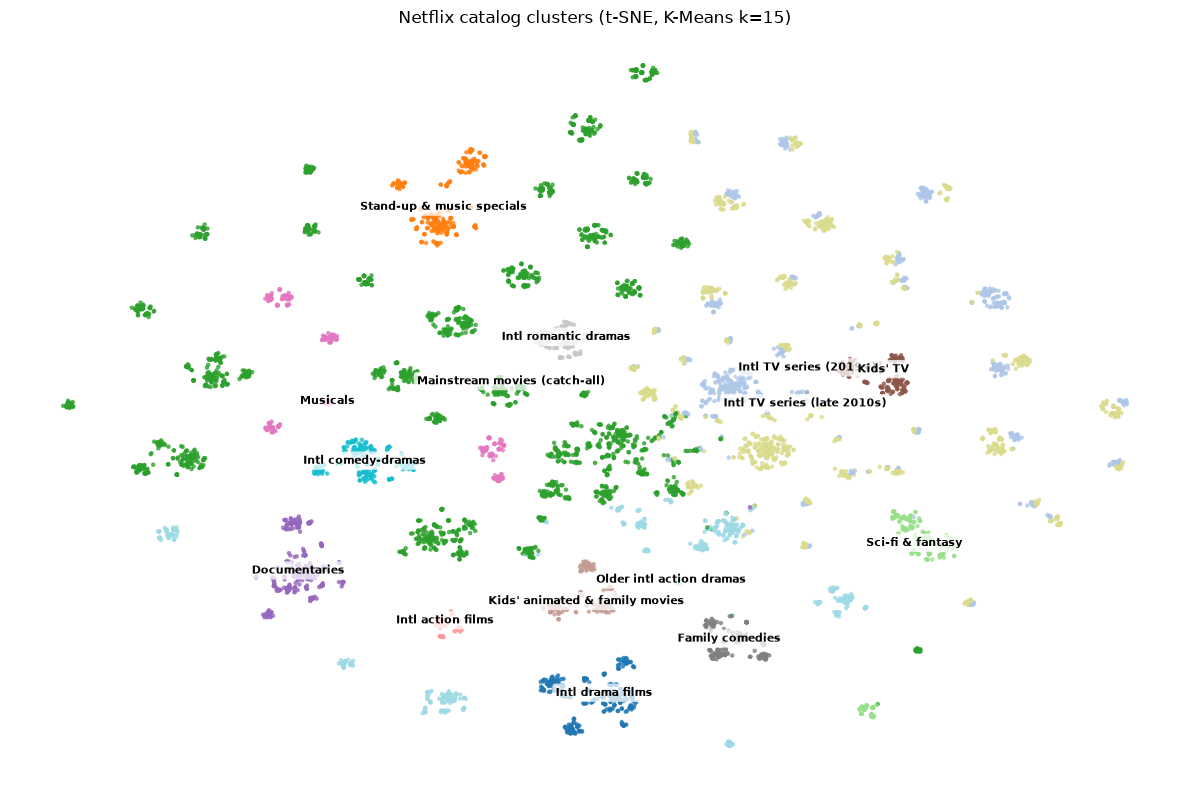

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

names = {
    0: "Intl drama films", 1: "Intl TV series (2019+)", 2: "Stand-up & music specials",
    3: "Mainstream movies (catch-all)", 4: "Sci-fi & fantasy", 5: "Intl action films",
    6: "Documentaries", 7: "Kids' TV", 8: "Kids' animated & family movies",
    9: "Musicals", 10: "Family comedies", 11: "Intl romantic dramas",
    12: "Intl TV series (late 2010s)", 13: "Intl comedy-dramas", 14: "Older intl action dramas",
}

xy = TSNE(n_components=2, perplexity=40, init="pca", random_state=42).fit_transform(Z)

fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(xy[:, 0], xy[:, 1], c=km_labels, cmap="tab20", s=5, alpha=0.7)
for c, name in names.items():
    cx, cy = np.median(xy[km_labels == c], axis=0)
    ax.text(cx, cy, name, fontsize=8, weight="bold", ha="center",
            bbox=dict(boxstyle="round", fc="white", alpha=0.75, lw=0))
ax.set_title("Netflix catalog clusters (t-SNE, K-Means k=15)")
ax.axis("off")
plt.tight_layout()
plt.savefig("../images/clusters_tsne.png", dpi=200)
plt.show()

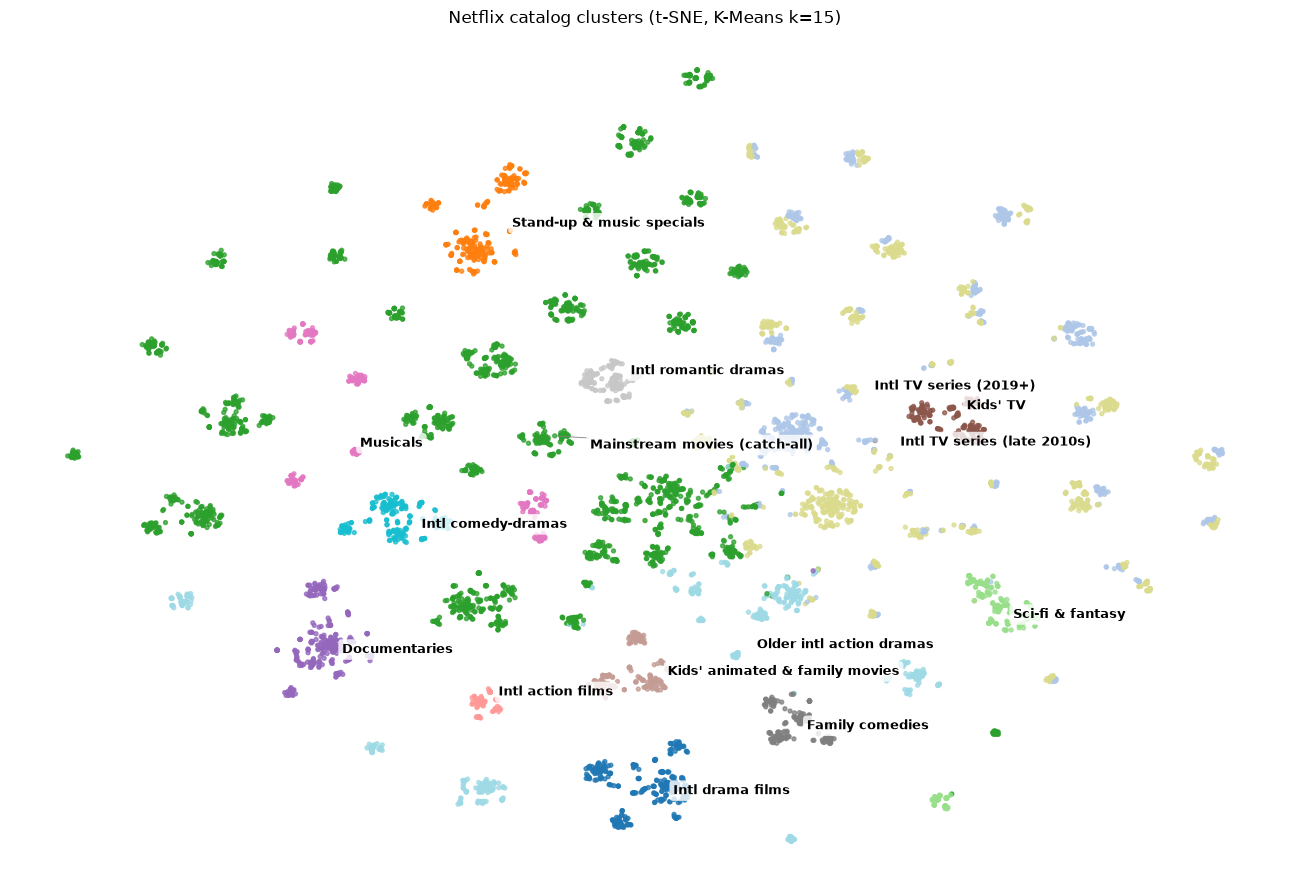

In [34]:
from adjustText import adjust_text

fig, ax = plt.subplots(figsize=(13, 9))
ax.scatter(xy[:, 0], xy[:, 1], c=km_labels, cmap="tab20", s=8, alpha=0.75)

texts = []
for c, name in names.items():
    pts = xy[km_labels == c]
    med = np.median(pts, axis=0)
    anchor = pts[np.argmin(((pts - med) ** 2).sum(axis=1))]  # nearest real point to the median
    texts.append(ax.text(anchor[0], anchor[1], name, fontsize=9, weight="bold",
                         bbox=dict(boxstyle="round", fc="white", alpha=0.8, lw=0)))

adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.6))
ax.set_title("Netflix catalog clusters (t-SNE, K-Means k=15)")
ax.axis("off")
plt.tight_layout()
plt.savefig("../images/clusters_tsne.png", dpi=200)
plt.show()

## 9. Save outputs

In [26]:
profile.to_csv("../outputs/cluster_profile.csv", index=False)
df.drop(columns=["text"]).to_csv("../outputs/netflix_clustered.csv", index=False)

## Cluster names
_Add your own, e.g. 0 = ..., 1 = ..., after reading the profile table._